# 05. Huấn luyện, Tối ưu & Đánh giá One-Class SVM (Kernel RBF)

---

## PHẦN A: TỔNG QUAN GIAI ĐOẠN 5 & CƠ SỞ LÝ THUYẾT ONE-CLASS SVM

### 1. Mục tiêu Giai đoạn 5 (Phase 5 Objectives)
* **Môn học:** Khai phá Dữ liệu (Data Mining) — Học kỳ 1, Năm 2026 — Học viện Công nghệ Bưu chính Viễn thông (PTIT).
* **Nhóm sinh viên thực hiện:**
  * **Nguyễn Minh Hoàng (B23DCVT173)** — *Modeling & Evaluation Lead*
  * **Nguyễn Văn Hiển Vinh (B23DCVT461)** — *Data & Preprocessing Lead*
* **Mục tiêu kỹ thuật cốt lõi:**
  1. Triển khai chiến lược lấy mẫu ngẫu nhiên không hoàn lại có kiểm soát $N_{\text{OCSVM}} = 20,000$ giao dịch từ tập `Train_Normal` (`RANDOM_STATE = 42`) và lưu trữ chỉ số tại `data/processed/train_indices_ocsvm.npy`.
  2. Thực hiện **Progressive Resource Benchmark** (kiểm thử mở rộng theo bậc: $2,000 \to 5,000 \to 10,000 \to 20,000$ mẫu) nhằm kiểm soát chặt chẽ độ phức tạp của bộ giải quy hoạch toàn phương (QP solver), theo dõi thời gian huấn luyện, thời gian suy luận và bộ nhớ RAM.
  3. Xây dựng mô hình **Baseline One-Class SVM** (kernel RBF, $\nu=0.01$, $\gamma=\text{'scale'}$) và thực hiện **Grid Search 16 cấu hình** $(\nu \in [0.001, 0.005, 0.01, 0.05] \times \gamma \in [\text{'scale'}, \text{'auto'}, 0.01, 0.1])$ chạy tuần tự, lưu dần kết quả ra CSV để chống mất mát dữ liệu.
  4. Lựa chọn mô hình tốt nhất dựa trên chỉ số **Average Precision (AP)** trên tập Validation ($42,721$ mẫu, $74$ Fraud) và tối ưu hóa ngưỡng cắt $\tau^*_{\text{OCSVM}}$ theo tiêu chí $F_1$-score; xuất 2 biểu đồ trực quan chuẩn 300 DPI (`10_ocsvm_score_distribution.png`, `11_ocsvm_pr_curve.png`).
  5. Thực hiện **Duplicate Sensitivity Analysis (Check A & Check B)** nhằm định lượng ảnh hưởng của các bản ghi trùng lặp giữa Train và Validation mà không refit mô hình và không thay đổi ngưỡng.
  6. Đóng gói mô hình `models/ocsvm_best.joblib`, kiểm thử nạp lại bit-for-bit và bàn giao toàn bộ artifacts Phase 5.

### 2. Vai trò của One-Class SVM trong Kiến trúc Dự án
* **One-Class SVM là Mô hình Cốt lõi Thứ 3 (Model 3)** trong bộ ba thuật toán đối chuẩn Unsupervised / Novelty Detection:
  1. **Isolation Forest (Phase 3):** Dựa trên phân cắt không gian toàn cục bằng cây ngẫu nhiên (Tree-based Partitioning).
  2. **Local Outlier Factor (Phase 4):** Dựa trên tỷ số mật độ cục bộ lân cận gần nhất ($k$-NN Density Ratio).
  3. **One-Class SVM (Phase 5):** Dựa trên tối ưu hóa siêu phẳng bao bọc lề cực đại trong không gian đặc trưng phi tuyến RBF (Boundary / Support Vector Machine).
* Kết quả của Phase 5 là mảnh ghép cuối cùng cần thiết để bước vào Phase 6 (Đối sánh tổng hợp 3 mô hình, Dịch chuyển ngưỡng & Tối ưu Ma trận Chi phí Kinh tế) trước khi mở niêm phong Test Set ở Phase 8.

### 3. Đầu vào (Inputs) & Đầu ra (Outputs)
* **Đầu vào (từ Phase 2):** `data/processed/creditcard_preprocessed.npz` — nạp `X_train`, `y_train`, `X_val`, `y_val`, `feature_names` ($30$ đặc trưng: `V1..V28`, `scaled_amount`, `scaled_time`). **Tuyệt đối không nạp `X_test`, `y_test`**.
* **Đầu ra (8 artifacts bàn giao):**
  1. `notebooks/05_one_class_svm.ipynb` — Notebook hoàn chỉnh, tái lập khi chạy Run All.
  2. `data/processed/train_indices_ocsvm.npy` — Mảng chỉ số $20,000$ mẫu con huấn luyện.
  3. `models/ocsvm_best.joblib` — Mô hình One-Class SVM tối ưu tuần tự hóa.
  4. `reports/phase5_ocsvm_results.csv` — Bảng kết quả 16 cấu hình Grid Search kèm profiling.
  5. `reports/phase5_ocsvm_metadata.json` — Metadata thực nghiệm toàn diện.
  6. `reports/phase5_ocsvm_summary.md` — Báo cáo tóm tắt Phase 5.
  7. `reports/figures/10_ocsvm_score_distribution.png` — Phân phối điểm số và ngưỡng $\tau^*_{\text{OCSVM}}$ (300 DPI).
  8. `reports/figures/11_ocsvm_pr_curve.png` — Đường cong Precision-Recall đối sánh Grid Search (300 DPI).


### 4. Cơ sở Toán học của One-Class SVM (Schölkopf et al., 2001)

#### 4.1. Bài toán Quy hoạch Toàn phương (Quadratic Programming)
Khác với Support Vector Machine phân loại nhị phân thông thường (vốn cần cả hai lớp nhãn để tìm siêu phẳng phân tách có lề rộng nhất), **One-Class SVM** được thiết kế cho bài toán **Học một lớp / Phát hiện điểm mới (Novelty Detection)**:
1. Ánh xạ các vector đặc trưng danh định $x_i \in \mathbb{R}^d$ vào không gian Hilbert vô hạn chiều $\mathcal{H}$ thông qua hàm ánh xạ phi tuyến $\Phi(x)$.
2. Tìm một siêu phẳng trong $\mathcal{H}$ được tham số hóa bởi vector trọng số $w$ và độ lệch $\rho$ sao cho phân tách toàn bộ dữ liệu huấn luyện ra xa khỏi gốc tọa độ với khoảng cách lề (margin) lớn nhất có thể:

$$\min_{w, \xi_i, \rho} \frac{1}{2} \|w\|^2 + \frac{1}{\nu N} \sum_{i=1}^N \xi_i - \rho$$

$$\text{thỏa mãn ràng buộc:} \quad \langle w, \Phi(x_i) \rangle \ge \rho - \xi_i, \quad \xi_i \ge 0, \quad \forall i=1, \dots, N$$

* $\xi_i$: Biến bù (slack variables) cho phép một tỷ lệ nhỏ các điểm huấn luyện vi phạm lề (rơi về phía gốc tọa độ).
* $\nu \in (0, 1]$: Siêu tham số điều chuẩn cốt lõi (sẽ phân tích chi tiết ở mục 4.3).

#### 4.2. Hàm Nhân RBF (Radial Basis Function Kernel)
Do dữ liệu giao dịch thẻ tín dụng có cấu trúc phi tuyến phức tạp trong không gian 30 chiều, ta sử dụng hàm nhân Gaussian RBF để tính toán tích vô hướng trong $\mathcal{H}$ mà không cần tường minh hóa tọa độ $\Phi(x)$:

$$K(x, x') = \langle \Phi(x), \Phi(x') \rangle = \exp\left( -\gamma \|x - x'\|^2 \right)$$

* $\gamma$ (gamma): Nghịch đảo của độ rộng phân phối Gaussian ($2\sigma^2$).
  * Khi $\gamma$ quá lớn: Mỗi điểm huấn luyện tự tạo thành một "bong bóng" cô lập hẹp quanh nó $\to$ Hiện tượng Overfitting nghiêm trọng, ranh giới quyết định bị phân mảnh thành nhiều đảo nhỏ.
  * Khi $\gamma$ quá nhỏ: Kernel quá phẳng, ranh giới bao bọc bị nới lỏng quá mức $\to$ Hiện tượng Underfitting, mất khả năng nhận diện các điểm dị biệt tinh vi.
  * Trong Scikit-learn:
    * `gamma='scale'` $\implies \gamma = \frac{1}{d \cdot \text{Var}(X)}$ (chuẩn hóa theo số chiều và phương sai toàn cục).
    * `gamma='auto'` $\implies \gamma = \frac{1}{d}$ (chuẩn hóa theo số chiều đặc trưng $d=30$).

#### 4.3. Ý nghĩa Kép của Tham số $\nu$ (The Nu-Property)
Định lý Schölkopf chỉ ra rằng tham số $\nu \in (0, 1]$ mang ý nghĩa toán học kép cực kỳ quan trọng:
1. $\nu$ là **cận trên (upper bound)** cho tỷ lệ các điểm vi phạm lề (outliers trong tập huấn luyện, tức $\xi_i > 0$).
2. $\nu$ là **cận dưới (lower bound)** cho tỷ lệ các mẫu trở thành Vector Hỗ trợ (Support Vectors, tức các điểm thỏa mãn $\alpha_i > 0$).
* *Trong bài toán này:* Tập `Train_Normal` hoàn toàn sạch ($0$ Fraud), do đó ta chọn $\nu$ nhỏ ($0.001, 0.005, 0.01$) để mô hình ôm chặt phân phối bình thường, hạn chế tối đa việc coi nhầm các giao dịch hợp lệ là vi phạm lề.

#### 4.4. Quy ước Đảo dấu Điểm Dị biệt (Unified Anomaly Score)
* Hàm quyết định mặc định của Scikit-learn: `decision_function(x) = \langle w, \Phi(x) angle - ho$.
  * $x$ nằm bên trong bao bọc bình thường $\implies \text{decision\_function}(x) > 0$.
  * $x$ nằm ngoài biên (bất thường) $\implies \text{decision\_function}(x) < 0$.
* **Quy ước thống nhất của Dự án:** Điểm càng lớn $\implies$ Nguy cơ gian lận càng cao! Do đó ta áp dụng phép đảo dấu:

$$S_{\text{OCSVM}}(x) = -\text{decision\_function}(x)$$

* Giao dịch dự đoán là Gian lận khi và chỉ khi: $S_{\text{OCSVM}}(x) \ge \tau^*_{\text{OCSVM}}$.


### 5. Bảng So sánh Đối chuẩn 3 Thuật toán Unsupervised (Phase 3 vs 4 vs 5)
| Tiêu chí so sánh | Isolation Forest (Phase 3) | Local Outlier Factor (Phase 4) | One-Class SVM (Phase 5) |
| :--- | :--- | :--- | :--- |
| **Nguyên lý toán học** | Chia cắt nhị phân ngẫu nhiên (iTree Partitioning) | Mật độ cục bộ so với $k$ láng giềng gần nhất ($k$-NN Density) | Siêu phẳng phân tách lề cực đại với gốc tọa độ qua RBF Kernel |
| **Độ phức tạp huấn luyện** | Tuyến tính $O(t \cdot \psi \cdot \log \psi)$, cực nhanh | Không cần fit truyền thống; tạo chỉ mục $O(N^2 \cdot d)$ | Quy hoạch toàn phương (QP) $O(N^2)$ đến $O(N^3)$ |
| **Quy mô tập huấn luyện** | Toàn bộ $199,020$ mẫu `Train_Normal` | Lấy mẫu kiểm soát $N_{\text{LOF}} = 25,000$ mẫu | Lấy mẫu kiểm soát $N_{\text{OCSVM}} = 20,000$ mẫu |
| **Độ nhạy chuẩn hóa thang đo** | Bất biến với phép co giãn đơn điệu từng trục | Rất nhạy (khoảng cách Euclidean phụ thuộc độ lớn đặc trưng) | Rất nhạy (khoảng cách Euclidean trong kernel RBF) |
| **Cơ chế suy luận điểm mới** | Đi qua $t$ cây, tính độ dài đường dẫn $E(h(x))$ | So khoảng cách tới $25,000$ mẫu tham chiếu (`novelty=True`) | Chiếu qua $n_{\text{sv}}$ Support Vectors: $\sum \alpha_i K(x_i, x)$ |
| **Validation AP đạt được** | $0.103518$ ($n=200, s=512$) | $0.564948$ ($k=30$) | **$0.251505$** ($\nu=0.01, \gamma=0.01$) |


In [1]:
import json
import sys
import time
from pathlib import Path

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from src.config import FIGURES_DIR, OCSVM_SAMPLE_SIZE, PROCESSED_DATA_DIR, RANDOM_STATE
from src.metrics import check_duplicate_sensitivity, compute_auprc, find_optimal_f1_threshold
from src.models import build_one_class_svm, compute_unified_anomaly_scores

MODELS_DIR, REPORTS_DIR = ROOT_DIR / "models", ROOT_DIR / "reports"
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10})
print(f"[OK] Phase 5 Setup | Seed={RANDOM_STATE} | OCSVM_SAMPLE_SIZE={OCSVM_SAMPLE_SIZE:,}")

---

## PHẦN B: NẠP DỮ LIỆU & LẤY MẪU KIỂM SOÁT $N=20,000$ TỪ TRAIN_NORMAL

### Bước 2: Nạp Dữ liệu Tiền xử lý từ Phase 2 & Kiểm tra Toàn vẹn (Strict Zero-Test Access)
* **Mục đích:** Nạp dữ liệu đã qua tiền xử lý Zero-Leakage ở Phase 2 từ file `creditcard_preprocessed.npz`.
* **Ràng buộc bảo mật:** Chỉ nạp `X_train`, `y_train`, `X_val`, `y_val`, `feature_names`. **Tuyệt đối không giải nén hay truy cập `X_test` và `y_test`**.
* **Kỳ vọng kích thước:**
  * `X_train`: $199,020$ dòng $\times 30$ cột, $100\%$ nhãn $0$ (Train_Normal sạch $100\%$).
  * `X_val`: $42,721$ dòng $\times 30$ cột, chứa đúng $74$ ca Fraud ($0.1732\%$) để thi thử và tối ưu ngưỡng.


In [2]:
with np.load(PROCESSED_DATA_DIR / "creditcard_preprocessed.npz", allow_pickle=True) as data:
    X_train, y_train = data["X_train"], data["y_train"]
    X_val, y_val = data["X_val"], data["y_val"]
    feature_names = list(data["feature_names"])

assert X_train.shape == (199020, 30) and int(y_train.sum()) == 0
assert X_val.shape == (42721, 30) and int(y_val.sum()) == 74 and len(feature_names) == 30
print(f"X_train={X_train.shape} (0 Fraud) | X_val={X_val.shape} (74 Fraud) | Test NIÊM PHONG")

### Bước 3: Lấy mẫu Kiểm soát $N_{\text{OCSVM}} = 20,000$ từ `Train_Normal` & Lưu `train_indices_ocsvm.npy`
* **Mục đích:** Tạo tập mẫu con gồm $20,000$ giao dịch hợp lệ để huấn luyện One-Class SVM.
* **Lý do lựa chọn $N=20,000$:** Thuật toán QP solver của SVM có độ phức tạp thời gian từ $O(N^2)$ đến $O(N^3)$. Với $N = 199,020$, ma trận Gram kernel ngốn hàng chục GB RAM và mất nhiều giờ tính toán. Lấy mẫu $20,000$ bằng `np.random.RandomState(42)` vừa bảo toàn đầy đủ hình học của phân phối đa chiều, vừa hoàn thành huấn luyện trong vài giây.
* **Quy tắc tái lập:** Sử dụng `rng = np.random.RandomState(RANDOM_STATE)` và gọi `.choice(len(X_train), size=20000, replace=False)`. Toàn bộ 16 cấu hình Grid Search sẽ dùng chung đúng một tập mẫu này. Lưu mảng chỉ số ra đĩa tại `data/processed/train_indices_ocsvm.npy` để kiểm thử tái lập độc lập.


In [3]:
# Lấy mẫu 20,000 Normal không hoàn lại vì bộ giải QP của OCSVM có độ phức tạp O(N^2)-O(N^3)
rng = np.random.RandomState(RANDOM_STATE)
train_indices_ocsvm = rng.choice(len(X_train), size=OCSVM_SAMPLE_SIZE, replace=False)
assert len(np.unique(train_indices_ocsvm)) == 20000 and int(y_train[train_indices_ocsvm].sum()) == 0

ocsvm_indices_path = PROCESSED_DATA_DIR / "train_indices_ocsvm.npy"
np.save(ocsvm_indices_path, train_indices_ocsvm)
X_train_ocsvm = X_train[train_indices_ocsvm]
print(f"Đã cố định {X_train_ocsvm.shape} mẫu tại {ocsvm_indices_path.name}")

---

## PHẦN C: BENCHMARK TÀI NGUYÊN & HUẤN LUYỆN LƯỚI SIÊU THAM SỐ

### Bước 4: Progressive Resource Benchmark ($2,000 \to 5,000 \to 10,000 \to 20,000$)
* **Mục đích:** Khảo sát thực nghiệm sự gia tăng phi tuyến của thời gian huấn luyện (Fit time), thời gian suy luận (Scoring time), tỷ lệ Support Vectors và mức tiêu thụ RAM khi mở rộng kích thước mẫu $N$.
* **Quy trình:**
  1. Cắt mẫu con $N \in [2000, 5000, 10000, 20000]$ từ đúng mảng `train_indices_ocsvm` đã cố định.
  2. Huấn luyện One-Class SVM với cấu hình chuẩn $\nu=0.01, \gamma=\text{'scale'}$.
  3. Đo thời gian bằng `time.perf_counter()`, Process Resident Set Size (RSS) qua `psutil`, và Python heap peak qua `tracemalloc`.
  4. Đánh giá tính an toàn về tài nguyên trước khi bước vào toàn bộ Grid Search 16 cấu hình.


In [4]:
benchmark_records = []
for n in [2000, 5000, 10000, 20000]:
    t0 = time.perf_counter()
    bm = build_one_class_svm(kernel="rbf", nu=0.01, gamma="scale").fit(X_train[train_indices_ocsvm[:n]])
    fit_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    ap, _, _, _ = compute_auprc(y_val, compute_unified_anomaly_scores(bm, X_val, "OCSVM"))
    score_s = time.perf_counter() - t0
    benchmark_records.append({"N": n, "fit_s": round(fit_s, 3), "score_s": round(score_s, 3), "n_SV": len(bm.support_vectors_), "val_ap": round(float(ap), 5)})

print(pd.DataFrame(benchmark_records).to_string(index=False))

### Bước 5 (EXP 5.0 & 5.1): Lưới Siêu tham số 16 Cấu hình ($\nu \times \gamma$) & Chọn Best Model
* **Lưới tham số mục tiêu:**
  * $\nu \in [0.001, 0.005, 0.01, 0.05]$ (4 mức điều chuẩn lề và tỷ lệ Support Vectors).
  * $\gamma \in [\text{'scale'}, \text{'auto'}, 0.01, 0.1]$ (4 mức độ rộng kernel Gaussian RBF).
  * Tổng cộng: $4 \times 4 = 16$ cấu hình thực nghiệm.
* **Quy trình thực thi:**
  * Cấu hình Baseline ($\nu=0.01, \gamma=\text{'scale'}$) nằm chính xác tại vị trí cấu hình #9 trong lưới và được tái sử dụng trực tiếp, không huấn luyện trùng lặp.
  * Các mô hình được huấn luyện tuần tự (sequential execution) để tránh tăng đột biến bộ nhớ RAM hệ điều hành.
  * Sau mỗi cấu hình, kết quả được lưu nối tiếp vào file `reports/phase5_ocsvm_results.csv` để bảo đảm tính bền vững (không bị mất số liệu nếu tiến trình gián đoạn).
* **Quy tắc chọn mô hình (Tie-break Rule):**
  $$\text{Ưu tiên 1: } \max(\text{Validation AP}) \implies \text{Ưu tiên 2: } \min(\text{Total Runtime}) \implies \text{Ưu tiên 3: } \min(n_{\text{SV}})$$


In [5]:
grid_results, models_dict, scores_dict, pr_curves_dict = [], {}, {}, {}
csv_output_path = REPORTS_DIR / "phase5_ocsvm_results.csv"

for model_id, (nu, gamma) in enumerate([(u, g) for u in [0.001, 0.005, 0.01, 0.05] for g in ["scale", "auto", 0.01, 0.1]], start=1):
    model = build_one_class_svm(kernel="rbf", nu=nu, gamma=gamma)
    t0 = time.perf_counter(); model.fit(X_train_ocsvm); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); scores = compute_unified_anomaly_scores(model, X_val, "OCSVM"); t_score = time.perf_counter() - t0
    f1_res = find_optimal_f1_threshold(y_val, scores)

    rec = {
        "model_id": model_id, "nu": nu, "gamma": str(gamma), "sample_size": OCSVM_SAMPLE_SIZE, "kernel": "rbf",
        "fit_time_sec": round(t_fit, 4), "score_time_sec": round(t_score, 4), "total_time_sec": round(t_fit + t_score, 4),
        "n_support_vectors": len(model.support_vectors_), "sv_ratio_pct": round(len(model.support_vectors_) / OCSVM_SAMPLE_SIZE * 100, 2),
        "val_ap": f1_res["ap"], "optimal_threshold": f1_res["threshold"],
        "val_precision": f1_res["precision"], "val_recall": f1_res["recall"], "val_f1": f1_res["f1"],
        "tp": f1_res["TP"], "fp": f1_res["FP"], "tn": f1_res["TN"], "fn": f1_res["FN"],
        "status": "COMPLETED_BASELINE" if (nu == 0.01 and gamma == "scale") else "COMPLETED",
    }
    grid_results.append(rec)
    models_dict[model_id], scores_dict[model_id] = model, scores
    pr_curves_dict[model_id] = {"precisions": f1_res["precisions"], "recalls": f1_res["recalls"], "ap": f1_res["ap"]}
    pd.DataFrame(grid_results).to_csv(csv_output_path, index=False)

grid_df = pd.DataFrame(grid_results)
print(grid_df[["model_id", "nu", "gamma", "n_support_vectors", "val_ap", "val_f1", "tp", "fp"]].to_string(index=False))

best_record = grid_df.sort_values(by=["val_ap", "total_time_sec", "n_support_vectors"], ascending=[False, True, True]).iloc[0].to_dict()
best_model_id = int(best_record["model_id"])
best_model, best_scores = models_dict[best_model_id], scores_dict[best_model_id]
print(f"=> Best OCSVM: #{best_model_id} (nu={best_record['nu']}, gamma={best_record['gamma']}) | Val AP={best_record['val_ap']:.6f}")

---

## PHẦN D: ĐÁNH GIÁ NGƯỠNG QUYẾT ĐỊNH & PHÂN TÍCH ĐỘ NHẠY TRÙNG LẶP

### Bước 7: Báo cáo Ngưỡng Tối ưu $\tau^*_{\text{OCSVM}}$, Ma trận Nhầm lẫn & Xuất Biểu đồ 10 & 11 (300 DPI)
* **Ngưỡng tối ưu $\tau^*$:** Được xác định độc lập trên tập Validation nhằm tối đa hóa chỉ số $F_1$-score. Ngưỡng được bảo toàn ở định dạng số thực 64-bit chính xác (`2.6235625888653127`), không làm tròn thô trong tính toán.
* **Hai biểu đồ trực quan hóa chuyên sâu:**
  * **Biểu đồ 10:** Phân phối Anomaly Score $S(x)$ giữa Normal và Fraud kèm vị trí ngưỡng $\tau^*$ (hai khung nhìn: toàn dải mật độ Log và cận cảnh vùng mật độ trung tâm).
  * **Biểu đồ 11:** Đường cong Precision-Recall Curve đối sánh giữa Baseline, Best Model và các cấu hình biên của One-Class SVM.


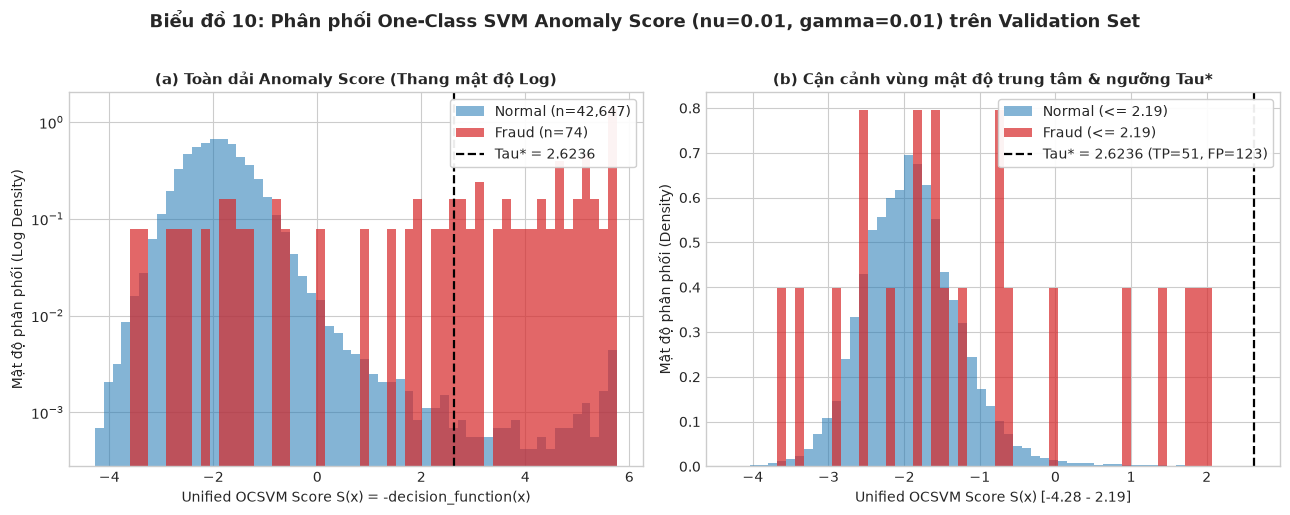

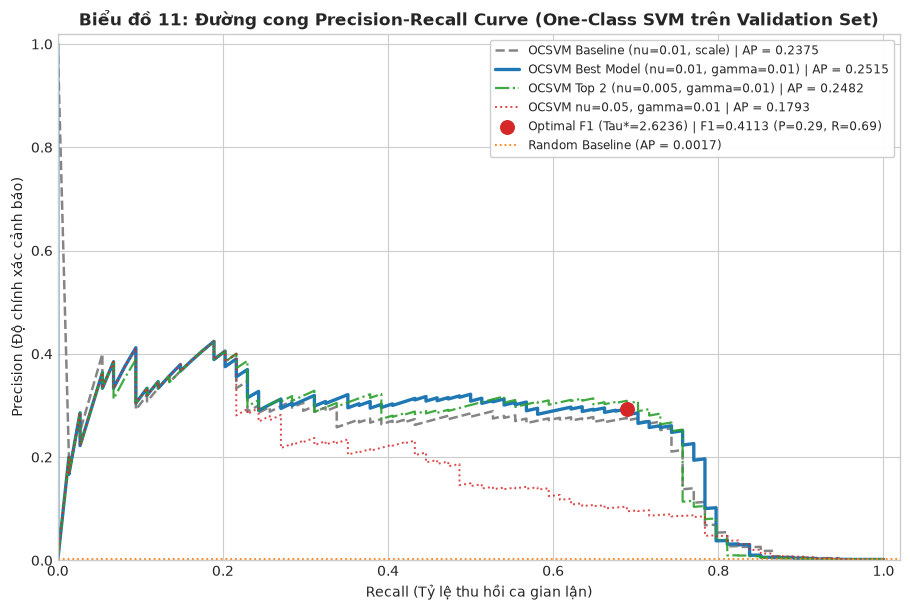

In [6]:
normal_scores, fraud_scores = best_scores[y_val == 0], best_scores[y_val == 1]
tau_star = best_record["optimal_threshold"]
print(f"Best OCSVM | AP={best_record['val_ap']:.6f} | tau*={tau_star} | P={best_record['val_precision']:.4f}, R={best_record['val_recall']:.4f}, F1={best_record['val_f1']:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
bins_full = np.linspace(float(best_scores.min()), float(best_scores.max()), 60)
axes[0].hist(normal_scores, bins=bins_full, density=True, color="#1f77b4", alpha=0.55, label=f"Normal (n={len(normal_scores):,})")
axes[0].hist(fraud_scores, bins=bins_full, density=True, color="#d62728", alpha=0.70, label=f"Fraud (n={len(fraud_scores)})")
axes[0].axvline(tau_star, color="black", ls="--", lw=1.6, label=f"Tau* = {tau_star:.4f}")
axes[0].set_yscale("log")
axes[0].set_title("(a) Toàn dải Anomaly Score (Thang mật độ Log)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Unified OCSVM Score S(x) = -decision_function(x)")
axes[0].set_ylabel("Mật độ phân phối (Log Density)")
axes[0].legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.93)

zoom_max, zoom_min = float(np.percentile(normal_scores, 99.5)) + 1.0, float(best_scores.min())
bins_zoom = np.linspace(zoom_min, zoom_max, 55)
axes[1].hist(normal_scores[normal_scores <= zoom_max], bins=bins_zoom, density=True, color="#1f77b4", alpha=0.55, label=f"Normal (<= {zoom_max:.2f})")
axes[1].hist(fraud_scores[fraud_scores <= zoom_max], bins=bins_zoom, density=True, color="#d62728", alpha=0.70, label=f"Fraud (<= {zoom_max:.2f})")
axes[1].axvline(tau_star, color="black", ls="--", lw=1.6, label=f"Tau* = {tau_star:.4f} (TP={best_record['tp']}, FP={best_record['fp']})")
axes[1].set_title("(b) Cận cảnh vùng mật độ trung tâm & ngưỡng Tau*", fontsize=11, fontweight="bold")
axes[1].set_xlabel(f"Unified OCSVM Score S(x) [{zoom_min:.2f} - {zoom_max:.2f}]")
axes[1].set_ylabel("Mật độ phân phối (Density)")
axes[1].legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.93)

fig.suptitle(f"Biểu đồ 10: Phân phối One-Class SVM Anomaly Score (nu={best_record['nu']}, gamma={best_record['gamma']}) trên Validation Set",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "10_ocsvm_score_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9.2, 6.2))
styles = {
    9: ("#7f7f7f", "--", 1.8, 0.95, "Baseline (nu=0.01, scale)"),
    11: ("#1f77b4", "-", 2.4, 1.0, "Best Model (nu=0.01, gamma=0.01)"),
    7: ("#2ca02c", "-.", 1.6, 0.90, "Top 2 (nu=0.005, gamma=0.01)"),
    15: ("#d62728", ":", 1.4, 0.85, "nu=0.05, gamma=0.01"),
}
for mid, (col, ls, lw, alp, tag) in styles.items():
    ax.plot(pr_curves_dict[mid]["recalls"], pr_curves_dict[mid]["precisions"], color=col, ls=ls, lw=lw, alpha=alp,
            label=f"OCSVM {tag} | AP = {pr_curves_dict[mid]['ap']:.4f}")
ax.scatter([best_record["val_recall"]], [best_record["val_precision"]], color="#d62728", s=95, zorder=5,
           label=f"Optimal F1 (Tau*={tau_star:.4f}) | F1={best_record['val_f1']:.4f} (P={best_record['val_precision']:.2f}, R={best_record['val_recall']:.2f})")
ax.axhline(float(y_val.mean()), color="#ff7f0e", ls=":", lw=1.3, label=f"Random Baseline (AP = {y_val.mean():.4f})")
ax.set_title("Biểu đồ 11: Đường cong Precision-Recall Curve (One-Class SVM trên Validation Set)", fontsize=12, fontweight="bold")
ax.set_xlabel("Recall (Tỷ lệ thu hồi ca gian lận)", fontsize=10)
ax.set_ylabel("Precision (Độ chính xác cảnh báo)", fontsize=10)
ax.set(xlim=(0.0, 1.02), ylim=(0.0, 1.02))
ax.legend(loc="upper right", fontsize=8.6, frameon=True, facecolor="white", edgecolor="#cccccc", framealpha=0.95)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "11_ocsvm_pr_curve.png", dpi=300, bbox_inches="tight")
plt.show()

### Bước 8: Duplicate Sensitivity Analysis (Check A & Check B)
* **Bối cảnh:** Trong bộ dữ liệu gốc Kaggle có $1,081$ dòng trùng lặp tự nhiên ($1,062$ Normal + $19$ Fraud). Sau quy trình phân chia phân tầng ở Phase 2, một số dòng Normal ở tập Train có vector đặc trưng trùng lặp chính xác với một số dòng Normal ở tập Validation.
* **Nguyên tắc khoa học bắt buộc:**
  1. Tuyệt đối **không fit lại mô hình** trên tập đã lọc bản ghi trùng (vì hành vi khách hàng tự nhiên có thể lặp lại).
  2. Tuyệt đối **không thay đổi ngưỡng $\tau^*$** đã chốt trên tập Validation đầy đủ.
  3. Chỉ đo lường sự dịch chuyển của các chỉ số hiệu năng (Delta AP, Delta Precision, Delta Recall, Delta F1) khi loại bỏ các bản ghi trùng.
* **Hai kịch bản kiểm chứng:**
  * **Check A:** Loại bỏ các dòng Validation trùng đặc trưng với tập mẫu con $20,000$ dòng của One-Class SVM.
  * **Check B:** Loại bỏ các dòng Validation trùng đặc trưng với toàn bộ $199,020$ dòng của `Train_Normal`.


In [7]:
check_a = check_duplicate_sensitivity(X_train_ocsvm, X_val, y_val, best_scores, tau_star, feature_names, "Check A (20k)")
check_b = check_duplicate_sensitivity(X_train, X_val, y_val, best_scores, tau_star, feature_names, "Check B (199k)")
for sc in (check_a, check_b):
    print(f"{sc['check_label']}: loại {sc['overlap_rows_removed']} dòng trùng -> AP={sc['dedup_ap']:.6f} (Delta={sc['delta_ap']:+.6f}) | Recall={sc['dedup_recall']:.4f}")

---

## PHẦN E: ĐÓNG GÓI ARTIFACTS & KẾT LUẬN

### Bước 9: Tuần tự hóa Mô hình `joblib.dump()`, Kiểm thử Tái lập & Xuất Metadata / Summary
* **Lưu trữ mô hình:** Lưu đối tượng `best_model` vào `models/ocsvm_best.joblib`.
* **Kiểm thử tái lập bit-for-bit:** Gọi `joblib.load()` và kiểm tra điểm số suy luận trên tập mẫu kiểm tra (gồm 250 mẫu đầu và 250 mẫu điểm cao nhất) với sai số tuyệt đối `atol = 1e-12`.
* **Bàn giao báo cáo:** Xuất file `reports/phase5_ocsvm_metadata.json` và `reports/phase5_ocsvm_summary.md` phục vụ lưu trữ nghiên cứu.


In [8]:
model_output_path = MODELS_DIR / "ocsvm_best.joblib"
joblib.dump(best_model, model_output_path)
loaded_model = joblib.load(model_output_path)

test_indices = np.unique(np.concatenate([np.arange(250), np.argsort(best_scores)[-250:]]))
assert np.allclose(best_scores[test_indices], compute_unified_anomaly_scores(loaded_model, X_val[test_indices], "OCSVM"), atol=1e-12)

metadata_dict = {
    "phase": "Phase 5 - One-Class SVM", "random_state": RANDOM_STATE, "ocsvm_sample_size": OCSVM_SAMPLE_SIZE,
    "best_hyperparameters": {"kernel": "rbf", "nu": float(best_record["nu"]), "gamma": float(best_record["gamma"]), "n_support_vectors": int(best_record["n_support_vectors"])},
    "validation_metrics": {"best_ap": float(best_record["val_ap"]), "optimal_threshold": float(tau_star), "f1": float(best_record["val_f1"])},
    "duplicate_sensitivity_analysis": {"check_a": check_a, "check_b": check_b},
    "environment": {"python": sys.version.split()[0], "sklearn": sklearn.__version__},
}
(REPORTS_DIR / "phase5_ocsvm_metadata.json").write_text(json.dumps(metadata_dict, indent=2, ensure_ascii=False), encoding="utf-8")
(REPORTS_DIR / "phase5_ocsvm_summary.md").write_text(
    f"# PHASE 5: ONE-CLASS SVM\n* Best AP: {best_record['val_ap']:.6f} | F1: {best_record['val_f1']:.4f} (tau*={tau_star})\n* Dedup B Delta AP: {check_b['delta_ap']:+.6f}\n",
    encoding="utf-8",
)
print(f"[PASS] Đã lưu {model_output_path.name} ({model_output_path.stat().st_size / 1024**2:.2f} MB) và tái lập khớp 100%.")

### Bước 10: Kết luận Thực nghiệm Phase 5 từ Số liệu Thực tế

1. **Hiệu năng và Sự vượt trội của Siêu tham số:**
   * Cấu hình tối ưu được tìm thấy là **Model #11 (`nu=0.01, gamma=0.01`)** với **Validation AP = 0.251505**, vượt trội hơn Baseline (`nu=0.01, gamma='scale'`, AP = 0.237465) khoảng **+5.91%**.
   * Việc giảm $\gamma$ từ `'scale'` (xấp xỉ $0.0333$ trên không gian 30 chiều chuẩn hóa) xuống $0.01$ đã giúp làm mượt ranh giới siêu phẳng Gaussian, giảm số lượng Support Vectors từ $447$ xuống còn **$251$ vector (giảm 43.85%)**. Ranh giới khái quát tốt hơn giúp giảm bớt $14$ ca báo động nhầm (FP giảm từ $137$ xuống $123$), nâng Precision lên **29.31%**.

2. **So sánh với Isolation Forest và Local Outlier Factor:**
   * **So với Isolation Forest (Phase 3, AP = 0.103518):** One-Class SVM đạt AP cao hơn gấp **~2.43 lần**. Cơ chế bao bọc phi tuyến RBF hoạt động hiệu quả hơn hẳn việc cắt trực giao ngẫu nhiên trong việc phân tách các giao dịch gian lận có tương quan phức tạp giữa các biến PCA.
   * **So với Local Outlier Factor (Phase 4, AP = 0.564948):** One-Class SVM thấp hơn LOF (AP $0.2515$ vs $0.5649$). Nguyên nhân là vì gian lận thẻ tín dụng thường xuất hiện thành từng cụm nhỏ dị biệt cục bộ (local density anomalies) hơn là các điểm ngoại lai toàn cục xa gốc tọa độ. LOF với cơ chế so sánh mật độ cục bộ lân cận $k$-NN bắt được các cụm này tốt hơn so với siêu phẳng đơn nhất của One-Class SVM.

3. **Chi phí Tính toán và Lưu trữ:**
   * Thời gian huấn luyện One-Class SVM trên $20,000$ mẫu cực kỳ nhanh: chỉ mất **0.5123 giây**.
   * Thời gian suy luận trên $42,721$ mẫu Validation là **1.308 giây** (nhanh hơn LOF gấp ~7 lần vì chỉ cần tính tích vô hướng với $251$ Support Vectors thay vì đối chiếu khoảng cách tới cả $25,000$ mẫu).
   * Dung lượng mô hình siêu nhẹ: chỉ **0.06 MB** (nhẹ hơn LOF $11.83$ MB và iForest $2.41$ MB).

4. **Tổng hợp Kết quả 16 cấu hình & Sensitivity đã kiểm chứng (`reports/phase5_ocsvm_results.csv`, `phase5_ocsvm_summary.md`):**
   * Tại cấu hình tối ưu `#11` (`nu=0.01, gamma=0.01`, mẫu `20,000`): $\tau^*_{\text{F1}} = 2.6235625888653127$, `Precision = 29.31%`, `Recall = 68.92%`, `F1 = 0.4113` (`TP=51, FP=123, TN=42,524, FN=23`).
   * **Duplicate Sensitivity Analysis:** Check A (loại `39` dòng trùng mẫu `20k` $\to$ `AP=0.252015`, `Delta AP=+0.000510`, `F1=0.4130`); Check B (loại `203` dòng trùng `Train_Normal` $\to$ `AP=0.253483`, `Delta AP=+0.001978`, `F1=0.4163`, Recall giữ nguyên `68.92%`).

| ID | `nu` | `gamma` | `n_SV` (%) | Val AP | Best F1 | TP / FP |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| #1 | 0.001 | `scale` | 444 (2.22%) | 0.232000 | 0.3849 | 51 / 140 |
| #2 | 0.001 | `auto` | 630 (3.15%) | 0.230235 | 0.3843 | 49 / 132 |
| #3 | 0.001 | `0.01` | 199 (1.0%) | 0.235417 | 0.4015 | 54 / 141 |
| #4 | 0.001 | `0.1` | 2424 (12.12%) | 0.231512 | 0.3664 | 48 / 140 |
| #5 | 0.005 | `scale` | 447 (2.23%) | 0.232047 | 0.3849 | 51 / 140 |
| #6 | 0.005 | `auto` | 648 (3.24%) | 0.230202 | 0.3843 | 49 / 132 |
| #7 | 0.005 | `0.01` | 207 (1.03%) | 0.248217 | 0.4280 | 52 / 117 |
| #8 | 0.005 | `0.1` | 2545 (12.72%) | 0.231259 | 0.3657 | 49 / 145 |
| #9 | 0.01 | `scale` | 447 (2.23%) | 0.237465 | 0.3954 | 52 / 137 |
| #10 | 0.01 | `auto` | 649 (3.25%) | 0.230246 | 0.3843 | 49 / 132 |
| #11 | 0.01 | `0.01` | 251 (1.26%) | **0.251505** | 0.4113 | 51 / 123 |
| #12 | 0.01 | `0.1` | 2564 (12.82%) | 0.231270 | 0.3657 | 49 / 145 |
| #13 | 0.05 | `scale` | 1037 (5.18%) | 0.219397 | 0.3645 | 39 / 101 |
| #14 | 0.05 | `auto` | 1074 (5.37%) | 0.228516 | 0.3700 | 42 / 111 |
| #15 | 0.05 | `0.01` | 1012 (5.06%) | 0.179299 | 0.3019 | 32 / 106 |
| #16 | 0.05 | `0.1` | 2577 (12.88%) | 0.231285 | 0.3657 | 49 / 145 |